In [117]:
from rdkit import Chem
import csv
import numpy as np
import pandas as pd
DATASET_PATH = 'data/mech-USPTO-31k.csv'
from matplotlib.colors import ListedColormap
# Example: define your own RGB color palette
# Replace these tuples with your desired RGB codes (values between 0 and 1)
custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

In [73]:
from pathlib import Path

viewer_indices = []

full_dict = {}

def process_reaction_files(filenames):
    success_indices = []
    failed_indices = []
    reaction_types = {}
    all_indices = []
    unique_mechs = 0
    test_set_mechs = 0

    for filename in filenames:
        terminated = False
        found_line = False
        with open(filename, 'r') as f:
            for line in f:
                
                if found_line:
                    if terminated:
                        if rxn_type not in reaction_types:
                            reaction_types[rxn_type] = [1,0]
                        else:
                            reaction_types[rxn_type][0] += 1
                        if "No products found, not saving tree" in line:
                            failed_indices.append(rxn_idx)
                        else:
                            print(f"Reaction {rxn_idx}")
                            success_indices.append(rxn_idx)
                            reaction_types[rxn_type][1] += 1
                        found_line = False
                        
                    if "Reaction type:" in line:
                        rxn_type = line.strip().split(":")[-1].strip()
                        full_dict[rxn_idx].append(rxn_type)
                        if rxn_type not in ["DCC_condensation", "SN2" , "nucleophilic_attack_to_(thio)carbonyl_or_sulfonyl"]:
                            viewer_indices.append(rxn_idx)
                        
                    if "Terminating safely" in line:
                        terminated = True
                        continue
                    
                if "Unique mechanisms found:" in line:
                    unique_mechs += int(line.strip().split()[-1])
                if "Test set mechanisms found:" in line:
                    test_set_mechs += int(line.strip().split()[-1])

                if "Processing row" in line:
                    rxn_idx = int(line.strip().split()[-1])
                    all_indices.append(rxn_idx)
                    full_dict[rxn_idx] = []
                    found_line = True
                    terminated = False
    
    return success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs, all_indices

# Usage
# filenames = ['slurm-13974.out', 'slurm-13978.out', 'slurm-13979.out', 'slurm-13980.out', 'slurm-13981.out', 'slurm-13984.out', 'slurm-13985.out', 'slurm-13986.out', 'slurm-13987.out']  # Add your filenames here

filenums = [111545, 111546, 111547]
filenums = [113349, 113350, 113351, 113352]
filenums = [113376, 113377, 113378, 113379, 113380, 113381]
filenames = [f"slurm_out/slurm-{num}.out" for num in filenums]

# filenames = sorted([str(p) for p in Path('slurm_out').glob('*.out') if p.is_file()])
success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs, all_indices = process_reaction_files(filenames)


Reaction 713
Reaction 931
Reaction 3622
Reaction 3717
Reaction 6867
Reaction 9078
Reaction 9470
Reaction 11119
Reaction 13524
Reaction 14963
Reaction 16205
Reaction 17036
Reaction 17936
Reaction 18192
Reaction 18417
Reaction 18626
Reaction 20798
Reaction 23503
Reaction 25045
Reaction 26329
Reaction 28120
Reaction 29081
Reaction 29224
Reaction 120
Reaction 1080
Reaction 4193
Reaction 5089
Reaction 5726
Reaction 6627
Reaction 7838
Reaction 8567
Reaction 8824
Reaction 10232
Reaction 10979
Reaction 11329
Reaction 12044
Reaction 15529
Reaction 18867
Reaction 19848
Reaction 20651
Reaction 20748
Reaction 24648
Reaction 30124
Reaction 30866
Reaction 31014
Reaction 12
Reaction 230
Reaction 327
Reaction 3068
Reaction 6226
Reaction 6828
Reaction 9603
Reaction 10505
Reaction 10926
Reaction 12577
Reaction 13835
Reaction 15595
Reaction 21408
Reaction 21745
Reaction 23601
Reaction 24611
Reaction 26224
Reaction 26348
Reaction 26427
Reaction 26961
Reaction 28203
Reaction 29185
Reaction 98
Reaction 1827

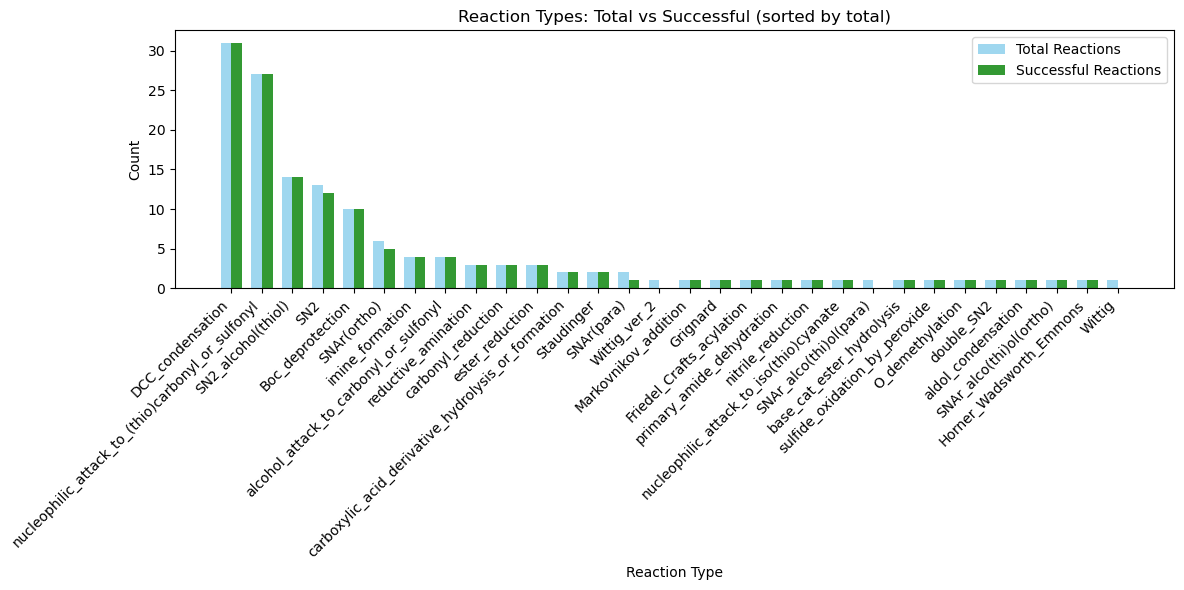

In [63]:
import matplotlib.pyplot as plt

# Extract and sort by total descending
categories = list(reaction_types.keys())
total = [reaction_types[cat][0] for cat in categories]
successful = [reaction_types[cat][1] for cat in categories]

pairs = sorted(zip(categories, total, successful), key=lambda t: t[1], reverse=True)
if pairs:
    categories_sorted, total_sorted, successful_sorted = zip(*pairs)
else:
    categories_sorted, total_sorted, successful_sorted = [], [], []

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(categories_sorted))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], total_sorted, width, label='Total Reactions', color='skyblue', alpha=0.8)
bars2 = ax.bar([i + width/2 for i in x], successful_sorted, width, label='Successful Reactions', color='green', alpha=0.8)

ax.set_xlabel('Reaction Type')
ax.set_ylabel('Count')
ax.set_title('Reaction Types: Total vs Successful (sorted by total)')
ax.set_xticks(x)
ax.set_xticklabels(categories_sorted, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()
# plt.savefig('plots/reaction_types_comparison_sorted.png', dpi=600)

In [85]:
for i in list(set(all_indices) - set(success_indices) - set(failed_indices)):
    print(i, full_dict[i])

19841 ['reductive_amination']
454 ['aldol_condensation']
30919 ['SNAr(para)']
24012 ['reductive_amination']
7277 ['reductive_amination']
17102 ['Wolf_Kishner_reduction']
5934 ['double_SN2']
14227 ['reductive_amination']
15992 ['Jones_oxidation']
25055 ['Paal_Knorr_pyrrole_synthesis']


In [65]:
print(all_indices)

[22, 713, 931, 3622, 3717, 6867, 9078, 9470, 11119, 13524, 14963, 16205, 17036, 17936, 18192, 18417, 18626, 20798, 23503, 24012, 25045, 26329, 28120, 29081, 29224, 120, 1080, 4193, 5089, 5726, 6627, 7277, 7838, 8567, 8824, 10232, 10979, 11329, 12044, 15529, 17102, 18867, 19848, 20651, 20748, 24648, 25228, 30124, 30866, 31014, 12, 230, 327, 3068, 6226, 6828, 9603, 10505, 10926, 11172, 12577, 13835, 15595, 17289, 21408, 21745, 23601, 24611, 25055, 26224, 26348, 26427, 26961, 28203, 29185, 98, 1827, 1995, 2192, 3064, 6173, 6308, 6754, 7734, 8136, 10225, 11935, 12718, 14650, 15111, 19006, 21008, 21146, 21441, 21511, 25033, 28698, 29771, 30080, 30560, 512, 1526, 3641, 5934, 7544, 8705, 8993, 9360, 10706, 11474, 13643, 14543, 14780, 15992, 16914, 18368, 19841, 25041, 25315, 25668, 26137, 26398, 27397, 28164, 28241, 454, 1024, 2235, 2461, 5931, 7237, 8769, 9411, 12464, 14227, 14594, 15386, 18286, 19339, 20253, 21102, 24376, 24545, 25154, 25590, 25842, 26747, 27249, 28573, 30919]


In [66]:
print("Successful reaction indices:", success_indices)
print("Failed reaction indices:", failed_indices)
print("Others:")
print("Percentage success", len(success_indices)/(len(success_indices)+len(failed_indices))*100)
print("Unique mechanisms found:", unique_mechs)
print("Test set mechanisms found:", test_set_mechs)
print("Percentage of recall from training data:", test_set_mechs/(unique_mechs+test_set_mechs)*100)
print("Total reactions analysed: ", len(success_indices)+len(failed_indices))

Successful reaction indices: [713, 931, 3622, 3717, 6867, 9078, 9470, 11119, 13524, 14963, 16205, 17036, 17936, 18192, 18417, 18626, 20798, 23503, 25045, 26329, 28120, 29081, 29224, 120, 1080, 4193, 5089, 5726, 6627, 7838, 8567, 8824, 10232, 10979, 11329, 12044, 15529, 18867, 19848, 20651, 20748, 24648, 30124, 30866, 31014, 12, 230, 327, 3068, 6226, 6828, 9603, 10505, 10926, 12577, 13835, 15595, 21408, 21745, 23601, 24611, 26224, 26348, 26427, 26961, 28203, 29185, 98, 1827, 1995, 2192, 3064, 6173, 6308, 6754, 7734, 8136, 10225, 11935, 12718, 14650, 15111, 19006, 21008, 21146, 21441, 21511, 25033, 28698, 29771, 30080, 30560, 512, 1526, 3641, 7544, 8705, 8993, 9360, 10706, 11474, 13643, 14543, 14780, 16914, 18368, 25041, 25315, 25668, 26137, 26398, 27397, 28164, 28241, 1024, 2235, 2461, 5931, 7237, 9411, 12464, 14594, 15386, 18286, 19339, 20253, 21102, 24376, 25154, 25590, 25842, 26747, 27249, 28573]
Failed reaction indices: [22, 25228, 11172, 17289, 8769, 24545]
Others:
Percentage succe

In [67]:
from IPython.display import display
from ipywidgets import Button, Output, VBox, HBox, Dropdown, HTML
import pandas as pd
import csv
from rdkit import Chem

# Load the CSV file
with open(DATASET_PATH, 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

# Create interactive viewer
current_idx = {'value': 0}
failed_to_show = failed_indices.copy()

reasons = {}

output_display = Output()
reason_input = Dropdown(
    options=[('Select reason...', ''), ('not possible', 'not possible'), ('fixed', 'fixed'),
            ('need more steps', 'need more steps'), ('stereochemistry', 'stereochemistry'),
            ('stoichiometry', 'stoichiometry'), ('retrain', 'retrain'), ('filtered', 'filtered'), ('other', 'other')],
    value=''
)

def show_reaction(idx):
    with output_display:
        output_display.clear_output()
        if idx >= len(failed_to_show):
            print("No more reactions to review")
            return

        row_num = failed_to_show[idx] - 1
        rxn = rows[row_num][1].split('>>')
        sm = Chem.MolFromSmiles(rxn[0])
        prod = Chem.MolFromSmiles(rxn[1])

        for atom in sm.GetAtoms():
            atom.SetAtomMapNum(0)
        for atom in prod.GetAtoms():
            atom.SetAtomMapNum(0)

        print(f"Reaction {idx + 1}/{len(failed_to_show)} - Row: {row_num + 1}")
        print(f"Type: {rows[row_num][2]}")
        print(f"SMILES: {Chem.MolToSmiles(sm)} >> {Chem.MolToSmiles(prod)}")
        display(Chem.Draw.MolToImage(sm))
        display(Chem.Draw.MolToImage(prod))

def on_next(b):
    current_idx['value'] += 1
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_prev(b):
    current_idx['value'] = max(0, current_idx['value'] - 1)
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_save(b):
    if current_idx['value'] < len(failed_to_show) and reason_input.value:
        reasons[failed_to_show[current_idx['value']]] = reason_input.value
        print(f"Saved reason: {reason_input.value}")

prev_btn = Button(description='Previous')
next_btn = Button(description='Next')
save_btn = Button(description='Save Reason')

prev_btn.on_click(on_prev)
next_btn.on_click(on_next)
save_btn.on_click(on_save)

show_reaction(0)
display(VBox([output_display, reason_input, HBox([prev_btn, save_btn, next_btn])]))

In [53]:
# reorganise reasons -> rows
reason_to_rows = {}
for row, reason in reasons.items():
    reason_to_rows.setdefault(reason, []).append(row)

# sort rows for each reason
for k in reason_to_rows:
    reason_to_rows[k].sort()

print(reason_to_rows)



{}


In [54]:
# reason_to_rows = {'not possible': [27063, 29433], 'fixed': [28653], 'need more steps': [730, 11249, 13287, 15205, 23156], 'filtered': [6027, 19960, 30636]}


In [68]:
from ipywidgets import Output, Button, VBox, HBox, Checkbox, HTML, Dropdown
from IPython.display import display, HTML as DispHTML
import re
import os
import pickle
import json
from rdkit.Chem import Draw

with open(DATASET_PATH, 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

def _visualise_tree(node):
    # collect nodes from root -> leaf
    nodes = []
    cur = node
    nodes.append(cur)
    while not cur.is_root:
        cur = cur.parent
        nodes.append(cur)
    nodes.reverse()

    smiles = [getattr(n, "smiles", None) for n in nodes]
    # use mech attribute
    mechs = [getattr(n, "mech", None) for n in nodes]

    mols = [Chem.MolFromSmiles(s) if s is not None else None for s in smiles]
    # produce image (keep same layout as before)
    image = Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=(400, 400),
        legends=[f"Mol {i}" for i in range(len(mols))],
    )

    # print annotations after visualization creation
    for i, (s, m) in enumerate(zip(smiles, mechs)):
        print(f"Mol {i}: [{s}], [{m}]")

    # return image, then smiles list, then mechanisms list and mol objects
    return (image, mols, mechs)


def _get_node_from_slurm(slurm_id):
    node = None
    for path in [
        f"old_slurm/slurm-{slurm_id}.out",
        f"slurm_out/slurm-{slurm_id}.out",
        f"slurm-{slurm_id}.out",
    ]:
        try:
            with open(path, "r") as f:
                lines = f.readlines()
            for line in lines:
                if "Running on master node:" in line:
                    node = line.split(":")[-1].split(".")[0].strip()
                    return node
        except Exception:
            continue
    return None


def _load_and_visualize_tree(slurm_id, node_dir_root="/nodescratch", row_id=None):
    node = _get_node_from_slurm(slurm_id)
    if node is None:
        raise RuntimeError(f"Could not find slurm output for {slurm_id}")

    node_dir = os.path.join(node_dir_root, node, "rd611", str(slurm_id))
    if not os.path.isdir(node_dir):
        raise RuntimeError(f"Node directory not found: {node_dir}")

    files = os.listdir(node_dir)
    if len(files) == 1:
        filename = files[0]
        pickle_path = os.path.join(node_dir, filename)
        with open(pickle_path, "rb") as file:
            node = pickle.load(file)
        image, mols, mechs = _visualise_tree(node)
        return ([(None, image)], mols, mechs)

    out_images = []
    last_mols = None
    last_mechs = None
    for filename in files:
        if filename.startswith(str(slurm_id)) and filename.endswith(".pkl"):
            parts = filename.split(".")[0].split("_")[1:]
            suffix = "_".join(parts) if parts else ""
            if suffix.split("_")[0] == str(row_id):
                pickle_path = os.path.join(node_dir, filename)
                with open(pickle_path, "rb") as file:
                    node = pickle.load(file)
                image, mols, mechs = _visualise_tree(node)
                out_images.append((suffix, image))
                last_mols = mols
                last_mechs = mechs
    return (out_images, last_mols, last_mechs)


def _find_slurm_for_row(row_id, search_dirs, pattern):
    row_id_str = str(row_id)
    row_re = re.compile(pattern.format(row_id=re.escape(row_id_str)))
    for d in search_dirs:
        if not os.path.isdir(d):
            continue
        for name in os.listdir(d):
            if not name.endswith(".out"):
                continue
            path = os.path.join(d, name)
            try:
                with open(path, "r", errors="ignore") as f:
                    text = f.read()
                if row_re.search(text):
                    # slurm-XXXXX.out
                    base = os.path.basename(name)
                    try:
                        slurm_id = int(base.split("-")[1].split(".")[0])
                        return slurm_id
                    except Exception:
                        continue
            except Exception:
                continue
    return None


def make_success_viewer_by_row(
    row_ids,
    search_dirs=None,
    row_pattern=r"\\b{row_id}\\b",
    node_dir_root="/nodescratch",
):
    """
    row_pattern is a regex template containing {row_id}. Default matches the
    row number as a standalone token. If your logs contain "Row: <id>",
    consider row_pattern=r"Row:\\s*{row_id}\\b".
    """

    if search_dirs is None:
        search_dirs = ["slurm_out", "old_slurm", "."]

    current_idx = {"value": 0}
    current_row = {"value": None}
    current_mols = {"value": None}
    current_mechs = {"value": None}
    output_display = Output()
    status = HTML()
    ratings = {}  # row_id -> "good", "bad", or None
    ignore_chk = {"value": False}

    good_chk = Checkbox(description="Good", value=False)
    bad_chk = Checkbox(description="Bad", value=False)
    can_find_good_chk = Checkbox(description="Can find good", value=False)

    # step selector and save button (use existing save_btn if present)
    step_sel = Dropdown(options=[], description="Bad step")
    if "save_btn" in globals():
        save_button = save_btn
    else:
        save_button = Button(description="Save Reason")

    def show_success(idx):
        with output_display:
            output_display.clear_output()
            if idx >= len(row_ids):
                print("No more reactions to review")
                return

            row_id = row_ids[idx]
            current_idx["value"] = idx
            current_row["value"] = row_id
            rxn = rows[row_id - 1][1].split('>>')
            sm = Chem.MolFromSmiles(rxn[0])
            prod = Chem.MolFromSmiles(rxn[1])

            for atom in sm.GetAtoms():
                atom.SetAtomMapNum(0)
            for atom in prod.GetAtoms():
                atom.SetAtomMapNum(0)
            status.value = f"<b>Success {idx + 1}/{len(row_ids)}</b> SMILES: {Chem.MolToSmiles(sm)} >> {Chem.MolToSmiles(prod)} <br> "
            slurm_id = _find_slurm_for_row(row_id, search_dirs, row_pattern)
            if slurm_id is None:
                print(f"No slurm output found containing row {row_id}")
                # update checkboxes to saved values or default
                ignore_chk["value"] = True
                rating = ratings.get(row_id)
                good_chk.value = rating == "good"
                bad_chk.value = rating == "bad"
                ignore_chk["value"] = False
                # clear step selector
                step_sel.options = []
                current_mols["value"] = None
                current_mechs["value"] = None
                return

            try:
                images, mols, mechs = _load_and_visualize_tree(
                    slurm_id, node_dir_root=node_dir_root, row_id=row_id
                )
            except Exception as e:
                print(f"Failed to visualize row {row_id} (slurm {slurm_id}): {e}")
                ignore_chk["value"] = True
                rating = ratings.get(row_id)
                good_chk.value = rating == "good"
                bad_chk.value = rating == "bad"
                ignore_chk["value"] = False
                step_sel.options = []
                current_mols["value"] = None
                current_mechs["value"] = None
                return

            # set checkboxes to saved values (without triggering save)
            ignore_chk["value"] = True
            rating = ratings.get(row_id)
            good_chk.value = rating == "good"
            bad_chk.value = rating == "bad"
            ignore_chk["value"] = False

            # store mols/mechs for save action
            current_mols["value"] = mols
            current_mechs["value"] = mechs

            # populate step selector if mols available
            if mols and len(mols) >= 2:
                options = [(f"Mol {i} -> Mol {i+1}", i) for i in range(len(mols) - 1)]
                step_sel.options = options
                step_sel.value = options[0][1]
            else:
                step_sel.options = []
                step_sel.value = None

            # images can be list[Image] (single) or list[(suffix, Image)] (multi)
            if images and isinstance(images[0], tuple):
                for suffix, image in images:
                    label = f"SLURM {slurm_id} — {suffix}" if suffix else f"SLURM {slurm_id}"
                    display(DispHTML(f"<div>{label}</div>"))
                    display(image)
            else:
                for image in images:
                    display(DispHTML(f"<div>SLURM {slurm_id}</div>"))
                    display(image)

    def on_next(_):
        current_idx["value"] += 1
        show_success(current_idx["value"])

    def on_prev(_):
        current_idx["value"] = max(0, current_idx["value"] - 1)
        show_success(current_idx["value"])

    def on_good_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            if change["new"]:
                ratings[row] = "good"
                bad_chk.value = False
            else:
                if ratings.get(row) == "good":
                    ratings[row] = None

    def on_bad_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            if change["new"]:
                ratings[row] = "bad"
                good_chk.value = False
            else:
                if ratings.get(row) == "bad":
                    ratings[row] = None

    def on_can_find_good_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            if change["new"]:
                ratings[row] = "can_find_good"
                good_chk.value = False
            else:
                if ratings.get(row) == "can_find_good":
                    ratings[row] = None

    def on_save_clicked(_):
        row = current_row["value"]
        mols = current_mols["value"]
        mechs = current_mechs["value"]
        sel = step_sel.value
        if row is None or mols is None or sel is None:
            print("No step selected or no mols available to save.")
            return
        first_idx = int(sel)
        mol_to_save = mols[first_idx]
        mech_choice = mechs[first_idx+1]
        out_dir = os.path.join("retrain", str(row))
        os.makedirs(out_dir, exist_ok=True)
        pkl_path = os.path.join(out_dir, "sm.pkl")
        with open(pkl_path, "wb") as f:
            pickle.dump(mol_to_save, f)
        choices = {"choices": {"0": {"mechanism": mech_choice, "probable": 0}}}
        with open(os.path.join(out_dir, "choices.json"), "w") as f:
            json.dump(choices, f)
        print(f"Saved sm.pkl and choices.json to {out_dir}")

    prev_btn = Button(description="Previous")
    next_btn = Button(description="Next")
    prev_btn.on_click(on_prev)
    next_btn.on_click(on_next)
    good_chk.observe(on_good_change, names="value")
    bad_chk.observe(on_bad_change, names="value")
    can_find_good_chk.observe(on_can_find_good_change, names="value")
    save_button.on_click(on_save_clicked)

    # layout: include step selector and save button
    controls = HBox([prev_btn, good_chk, bad_chk, can_find_good_chk, next_btn, step_sel, save_button])

    show_success(0)
    viewer = VBox([status, output_display, controls])
    viewer.ratings = ratings  # attach dict so caller can access saved ratings
    return viewer


__all__ = ["make_success_viewer_by_row"]


In [83]:
view_indices = list(set(viewer_indices).intersection(set(success_indices)))
view_indices = ns_rows

viewer = make_success_viewer_by_row(
    view_indices, search_dirs=["slurm_out"], row_pattern=r"Processing row\s*{row_id}\b",   # adjust if your logs differ
      node_dir_root="/nodescratch"
  )

display(viewer)

In [97]:
rows_retry = []
for k,v in viewer.ratings.items():
    if v == "can_find_good":
        rows_retry.append(k)
rows_retry

[]

In [102]:
full_dict[14963]

['reductive_amination']

In [ ]:
import matplotlib.pyplot as plt

# Assuming rows is loaded from 'mech-USPTO-31k.csv' as in previous cells
# If not already loaded, uncomment the following:
# with open('mech-USPTO-31k.csv', 'r') as f:
#     reader = csv.reader(f)
#     rows = list(reader)

# Initialize dict for counts per reaction type
type_to_counts = {}

# Get all unique reaction types from rows
all_types = set()
for row in rows:
    all_types.add(row[2])

for typ in all_types:
    type_to_counts[typ] = {'success': [[],0], 'other_mechs': [[],0], 'failed': [[],0]}

# Categorize successful reactions by type
for idx in success_indices:
    typ = rows[idx-1][2]
    if idx in viewer.ratings:
        rating = viewer.ratings[idx]
        if rating == 'good':
            type_to_counts[typ]['success'][1] += 1
            type_to_counts[typ]['success'][0].append(idx)
        elif rating == 'bad':
            type_to_counts[typ]['failed'][1] += 1
            type_to_counts[typ]['failed'][0].append(idx)

# Categorize failed reactions by type
for idx in failed_indices:
    typ = rows[idx-1][2]
    type_to_counts[typ]['failed'][1] += 1
    type_to_counts[typ]['failed'][0].append(idx)

# Prepare data for plotting: sort types by total count descending, but only include types with total > 0
type_totals = {}
for typ, counts in type_to_counts.items():
    type_totals[typ] = sum(counts[1].values())

sorted_types = [typ for typ in sorted(type_totals, key=type_totals.get, reverse=True) if type_totals[typ] > 0]

# Categories for bars
categories = ['success', 'other_mechs', 'failed']
colors = ['green', 'yellow', 'gray']

# Create two-panel figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left panel: Total successful/failed/unknown counts
total_successful = sum(type_to_counts[typ]['successful'] for typ in type_to_counts)
total_failed_or_bad = sum(type_to_counts[typ]['failed_or_bad'] for typ in type_to_counts)
total_unknown = sum(type_to_counts[typ]['unknown'] for typ in type_to_counts)

ax1.bar(['Successful', 'Failed/Bad', 'Unknown'], [total_successful, total_failed_or_bad, total_unknown], 
        color=['green', 'red', 'gray'], alpha=0.8)
ax1.set_ylabel('Count')
ax1.set_title(f'Overall Status Breakdown. Success rate {total_successful/(total_successful+total_failed_or_bad+total_unknown)%1}')
ax1.grid(axis='y', alpha=0.3)

# Right panel: Breakdown by reaction type (grouped bars)
x = range(len(sorted_types))
width = 0.25

for i, cat in enumerate(categories):
    values = [type_to_counts[typ][cat] for typ in sorted_types]
    ax2.bar([pos + i * width for pos in x], values, width, label=cat, color=colors[i], alpha=0.8)

ax2.set_xlabel('Reaction Type')
ax2.set_ylabel('Count')
ax2.set_title('Reaction Types: Breakdown by Status (sorted by total)')
ax2.set_xticks([pos + width * (len(categories) - 1) / 2 for pos in x])
ax2.set_xticklabels(sorted_types, rotation=45, ha='right')
ax2.legend()

plt.tight_layout()
plt.show()
plt.savefig('plots/reaction_types_status_breakdown.png', dpi=600)

In [ ]:
reaction_rows = []

In [88]:

with open('screen_analysis_121_part_1.txt', 'r') as f:
    for line in f:
        l = line.split(':')
        idx = int(l[0].strip())
        if l[1].strip().strip(',').strip("'") == "bad":
            row = rows[idx - 1]
            smiles = row[1]
            parts = [p.strip() for p in smiles.split(">>", 1)]
            reactant_smiles = parts[0]
            product_smiles = parts[1] if len(parts) > 1 else ""
            reaction_rows.append({
                "Row_Index": idx,
                "Reactant_SMILES": reactant_smiles,
                "Product_SMILES": product_smiles,
                "Reaction_Type": row[2],
                "Status": "failed",
            })

In [92]:
print(sn2_rows)

[13524, 26329, 28120, 29224, 120, 25228, 327, 26961, 2192, 3064, 11935, 28164, 2461]


In [111]:
status_df = pd.read_csv("reaction_status_v121.csv", index_col=False)
for idx in [4193, 11474]:

    row = rows[idx - 1]
    smiles = row[1]
    parts = [p.strip() for p in smiles.split(">>", 1)]
    reactant_smiles = parts[0]
    product_smiles = parts[1] if len(parts) > 1 else ""
    entry = {
        "Row_Index": idx,
        "Reactant_SMILES": reactant_smiles,
        "Product_SMILES": product_smiles,
        "Reaction_Type": row[2],
        "Status": "other_mechs",
    }
    status_df.loc[len(status_df)] = entry

status_df.to_csv("reaction_status_v121.csv", index=False)
print(f"Saved {len(status_df)} rows to 'reaction_status_v121.csv'")
status_df.head()

Saved 106 rows to 'reaction_status_v121.csv'


,Row_Index,Reactant_SMILES,Product_SMILES,Reaction_Type,Status
0,512,[O:4]=[C:5]1[CH2:6][C@@H:7]([SH:8])[CH2:9][N:1...,[CH2:1]([CH2:2][OH:3])[S:8][C@@H:7]1[CH2:6][C:...,SN2_alcohol(thiol),success
1,29185,[CH3:202][C:203]([CH3:204])([CH3:205])[O:206][...,[NH2:1][C@@H:2]([CH3:3])[c:4]1[cH:5][cH:6][c:7...,Boc_deprotection,success
2,1024,[NH2:5][C:6](=[O:7])[c:8]1[cH:9][cH:10][c:11](...,[CH2:1]([CH2:2][CH2:3][Cl:4])[O:12][c:11]1[cH:...,SN2_alcohol(thiol),success
3,30080,[CH3:5][O:6][c:7]1[cH:8][c:9]([CH2:10][CH:11]2...,[CH2:1]([CH:2]1[CH2:3][CH2:4]1)[O:39][c:38]1[c...,SN2_alcohol(thiol),success
4,21511,[O:3]=[C:4]1[c:5]2[cH:6][c:7]([OH:8])[cH:9][cH...,[CH2:1]([CH3:2])[O:8][c:7]1[cH:6][c:5]2[c:11](...,SN2_alcohol(thiol),success


In [113]:
status_df[status_df["Row_Index"] ==4193]

,Row_Index,Reactant_SMILES,Product_SMILES,Reaction_Type,Status
104,4193,[CH3:6][CH2:7][c:8]1[n:9][cH:10][n:11][c:12]([...,[C:1]([O:2][CH2:3][CH3:4])(=[O:5])[O:20][CH2:1...,alcohol_attack_to_carbonyl_or_sulfonyl,other_mechs


In [120]:
print(counts.columns)

Index(['failed', 'other_mechs', 'success'], dtype='object', name='Status')


In [134]:
counts.index

Index(['nucleophilic_attack_to_(thio)carbonyl_or_sulfonyl',
       'SN2_alcohol(thiol)', 'SN2', 'Boc_deprotection', 'SNAr(ortho)',
       'imine_formation', 'alcohol_attack_to_carbonyl_or_sulfonyl',
       'ester_reduction', 'carbonyl_reduction', 'SNAr(para)', 'Staudinger',
       'carboxylic_acid_derivative_hydrolysis_or_formation',
       'nitrile_reduction', 'nucleophilic_attack_to_iso(thio)cyanate',
       'primary_amide_dehydration', 'base_cat_ester_hydrolysis', 'double_SN2',
       'Wittig_ver_2', 'aldol_condensation', 'Wolf_Kishner_reduction',
       'Friedel_Crafts_acylation', 'Wittig', 'SNAr_alco(thi)ol(para)',
       'SNAr_alco(thi)ol(ortho)', 'Markovnikov_addition', 'Jones_oxidation',
       'Horner_Wadsworth_Emmons', 'Grignard', 'sulfide_oxidation_by_peroxide'],
      dtype='object', name='Reaction_Type')

Status
success        92
other_mechs     2
failed         12
dtype: int64


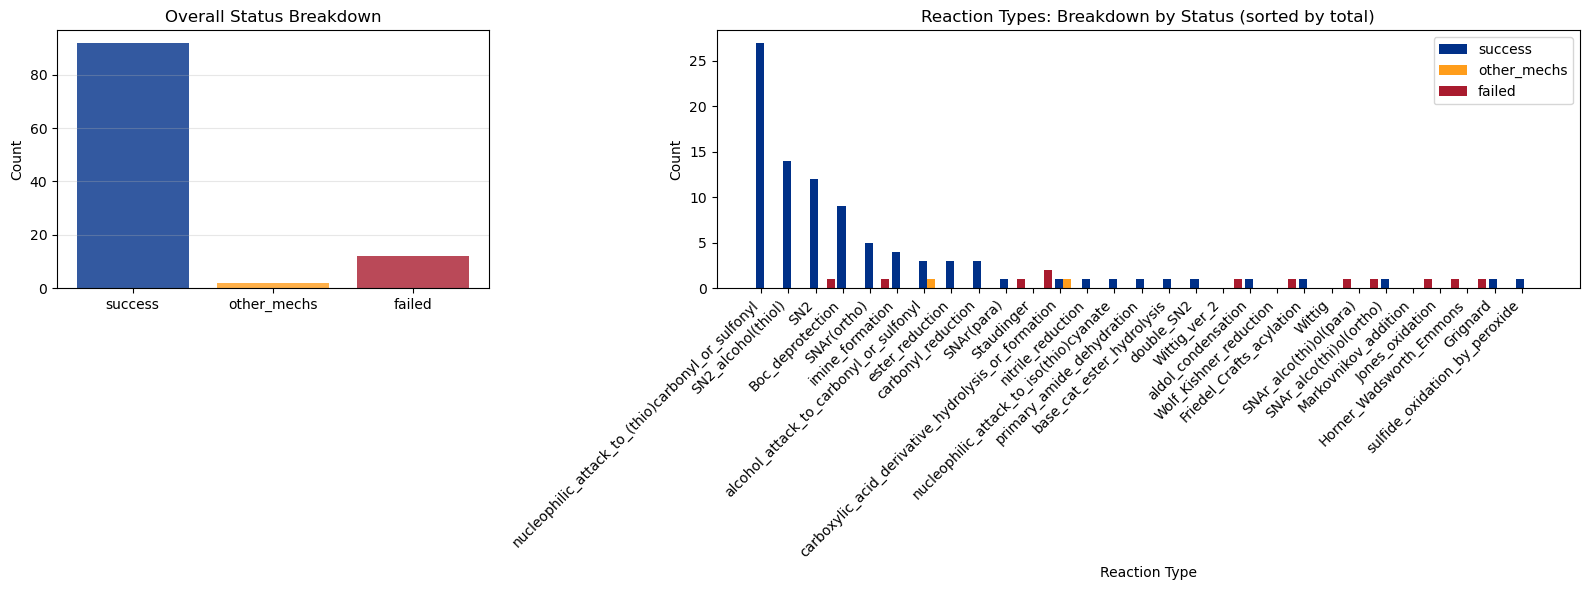

In [141]:
def load_reaction_status_csv(path="reaction_status.csv"):
    return pd.read_csv(path)

status_df = load_reaction_status_csv("reaction_status_v121.csv")
status_df.head()

counts = (
    status_df.groupby("Reaction_Type")["Status"]
      .value_counts()
      .unstack(fill_value=0)
)
counts = counts[['success', 'other_mechs', 'failed']]

counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
counts = counts.drop(columns="total")

totals = counts.sum(axis=0)
print(totals)

# type_to_counts = {}
# for _, row in status_df.iterrows():
#     typ = row["Reaction_Type"]
#     type_to_counts.setdefault(typ, {"successful": 0, "failed_or_bad": 0, "unknown": 0})
#     type_to_counts[typ][row["Plot_Status"]] += 1

# sorted_types = sorted(type_to_counts, key=lambda t: sum(type_to_counts[t].values()), reverse=True)

categories = ["successful", "failed_or_bad", "unknown"]
colours = ["#003088", "#FF9D1B", "#A91B2E"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2]})


ax1.bar(counts.columns, totals, color=colours, alpha=0.8)
ax1.set_ylabel("Count")
ax1.set_title("Overall Status Breakdown")
ax1.grid(axis="y", alpha=0.3)

x = np.arange(len(counts))
width = 0.9 / len(counts.columns)   # Total group width = 80% of spacing

for i, column in enumerate(counts.columns):
    ax2.bar(
        x + i * width,
        counts[column],
        width,
        label=column,
        color=colours[i]
    )

ax2.set_xlabel("Reaction Type")
ax2.set_ylabel("Count")
ax2.set_title("Reaction Types: Breakdown by Status (sorted by total)")
ax2.set_xticks([pos-4.3 + width * (len(counts) ) / 2 for pos in x])
ax2.set_xticklabels(counts.index, rotation=45, ha="right")
ax2.legend()

plt.tight_layout()
plt.show()

In [114]:
counts

Status,failed,other_mechs,success,total
Reaction_Type,,,,
nucleophilic_attack_to_(thio)carbonyl_or_sulfonyl,0,0,27,27
SN2_alcohol(thiol),0,0,14,14
SN2,1,0,12,13
Boc_deprotection,0,0,9,9
SNAr(ortho),1,0,5,6
imine_formation,0,0,4,4
alcohol_attack_to_carbonyl_or_sulfonyl,0,1,3,4
ester_reduction,0,0,3,3
carbonyl_reduction,0,0,3,3


In [ ]:
len(success_indices) - len(viewer.ratings)

1

In [ ]:
for k,v in reasons.items():
    if v == 'need more steps':
        print(k)

13512
8572
10096
495
20516
2442
837


as a general rule  
Carbonyl reduction - stereochemistry  
Nitrile reduction - need more steps  
Ester reduction - need more steps  
Wittig - not possible  
Horner-Wadsworth-Emmons -not possible  
Appel - not possible  
Ing-Maske - need more steps

In [ ]:
import pandas as pd

# Create a dataframe from the reasons dictionary
results_df = pd.DataFrame(list(reasons.items()), columns=['Row_Index', 'Reason'])

# Save to CSV
results_df.to_csv('failure_reasons_2.csv', index=False)

print(f"Saved {len(results_df)} results to 'failure_reasons.csv'")

Saved 16 results to 'failure_reasons.csv'


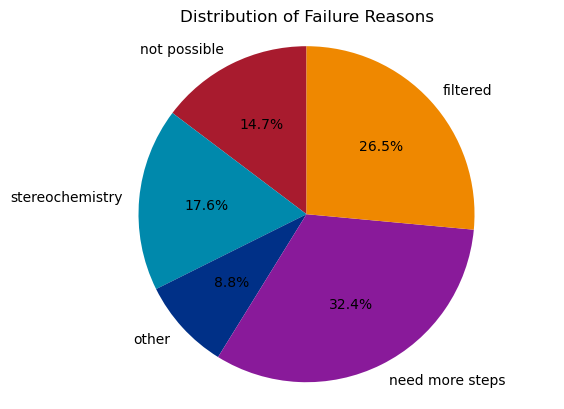

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

# Count the reasons
reason_counts = {}
for reason in reasons.values():
    reason_counts[reason] = reason_counts.get(reason, 0) + 1

# Create pie chart
labels = list(reason_counts.keys())
sizes = list(reason_counts.values())
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=custom_c)
ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Distribution of Failure Reasons')
plt.show()

In [ ]:
# Calculate true failures: only "not possible" and "filtered"
true_failures = sum(1 for reason in reasons.values() if reason in ["not possible", "filtered"])

# Total reactions
total_reactions = len(success_indices) + len(failed_indices)

# New failure rate
new_failure_rate = (true_failures / total_reactions) * 100 if total_reactions > 0 else 0

print(f"New success rate (only 'not possible' and 'filtered' as failures): {100 - new_failure_rate:.2f}%")

New success rate (only 'not possible' and 'filtered' as failures): 91.91%


In [ ]:
# Show all reactions labeled "other" or "filtered"
matches = [r for r, reason in reasons.items() if reason in ("other", "filtered")]

if not matches:
    print("No reactions labeled 'other' or 'filtered'.")
else:
    for row in sorted(matches):
        row_idx = row - 1
        rxn_line = rows[row_idx][1]
        parts = rxn_line.split(">>")
        react_smiles = parts[0].strip()
        prod_smiles = parts[1].strip() if len(parts) > 1 else ""
        sm = Chem.MolFromSmiles(react_smiles)
        prod = Chem.MolFromSmiles(prod_smiles) if prod_smiles else None
        if sm:
            for a in sm.GetAtoms():
                a.SetAtomMapNum(0)
        if prod:
            for a in prod.GetAtoms():
                a.SetAtomMapNum(0)
        print(f"Row {row} | Type: {rows[row_idx][2]} | Reason: {reasons[row]}")
        print(f"SMILES: {react_smiles} >> {prod_smiles}")
        display(Chem.Draw.MolToImage(sm))
        if prod:
            display(Chem.Draw.MolToImage(prod))

In [ ]:
with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    row = 0
    for l in reader:
        row += 1
        if row not in failed_indices:
            continue
        print("_"*40)
        print(f"Processing row {row}")
        print(l[1])
        print(f"Reaction type: {l[2]}")
        line = l[1]
        l_s = line.split(">>")
        reactant = l_s[0].strip()
        product = l_s[1].strip()
        try:
            run_parallel(reactant, product, str(row))
        except Exception as e:
            print(e)